# Constelación: filtro adaptado y temporización

Muestra 16QAM a 20 dB del set `ideal`.

## 1. Rutas

In [11]:
import sys
from pathlib import Path

import numpy as np

# Igual que en 09: subir desde la carpeta actual hasta encontrar data/train/X.npy.
current = Path.cwd().resolve()
ROOT = None

for folder in (current,) + tuple(current.parents):
    if (folder / "data" / "train" / "X.npy").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/train/X.npy subiendo desde {}.".format(current)
    )

# Sin esto, "import src" falla si el kernel arrancó dentro de notebooks/.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print(ROOT)

/home/lcmj2803/coms_proyecto2


## 2. Datos

In [12]:
import pandas as pd

# mmap_mode="r": no carga los 92 MB a RAM; lee del disco solo las filas que indexes.
X = np.load(ROOT / "data" / "ideal" / "X.npy", mmap_mode="r")
meta = pd.read_csv(ROOT / "data" / "ideal" / "meta.csv")

print(X.shape, X.dtype)
print(len(meta))

(11200, 2, 1024) float32
11200


## 3. Elegir la muestra

In [13]:
# Máscara booleana: True en las filas que cumplen las dos condiciones.
mask = (meta["mod"] == "16QAM") & (meta["snr_db"] == 20)
sel = meta[mask]

# La fila i de meta describe a X[i], así que el índice de la tabla sirve para X.
idx = int(sel.index[0])

print("filas que cumplen:", len(sel))
print("idx:", idx)
print(meta.loc[idx, ["mod", "snr_db", "snr_inst_db"]])

filas que cumplen: 100
idx: 6300
mod                16QAM
snr_db              20.0
snr_inst_db    20.048635
Name: 6300, dtype: object


## 4. Comprobaciones del filtro adaptado

In [14]:
from src.constelacion import H_RRC, a_complejo, filtro_adaptado

# (a) Energía unitaria del RRC.
print("sum(H_RRC^2) =", np.sum(H_RRC**2))

# (b) RRC * RRC = coseno alzado. Modo "full": 81 + 81 - 1 = 161 muestras, centro en 80.
g = np.convolve(H_RRC, H_RRC)
k = np.arange(-10, 11)          # 80 + 8k cae dentro de 0..160 para k = -10..10
print("len(g) =", len(g))
print("g[80 + 8k] =", np.round(g[80 + 8 * k], 4))

# (c) Observación -> señal compleja -> filtro adaptado.
y = a_complejo(X[idx])
z = filtro_adaptado(y)
print("y:", y.shape, y.dtype)
print("z:", z.shape, z.dtype)

sum(H_RRC^2) = 1.0
len(g) = 161
g[80 + 8k] = [ 0.0e+00  0.0e+00 -2.0e-04 -1.0e-04  1.7e-03 -5.8e-03  1.4e-03 -7.0e-04
  2.0e-04  1.0e-04  1.0e+00  1.0e-04  2.0e-04 -7.0e-04  1.4e-03 -5.8e-03
  1.7e-03 -1.0e-04 -2.0e-04  0.0e+00  0.0e+00]
y: (1024,) complex64
z: (944,) complex128


## 5. Temporización

energías: [2566.6935 2368.4272 2279.7933 2351.2601 2540.0977 2734.3523 2819.0442
 2742.0975]
k_best: 6


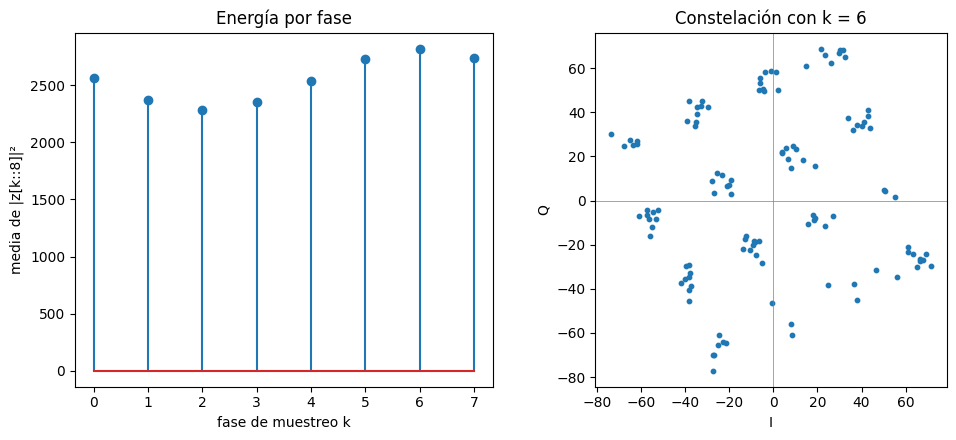

In [15]:
import matplotlib.pyplot as plt
from src.dataset import SPS

# Para cada fase k, z[k::SPS] toma una muestra por símbolo empezando en k.
energias = np.array([np.mean(np.abs(z[k::SPS]) ** 2) for k in range(SPS)])
k_best = int(np.argmax(energias))
print("energías:", np.round(energias, 4))
print("k_best:", k_best)

s = z[k_best::SPS]   # ~118 símbolos

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

ax1.stem(np.arange(SPS), energias)
ax1.set_xlabel("fase de muestreo k")
ax1.set_ylabel("media de |z[k::8]|²")
ax1.set_title("Energía por fase")

ax2.scatter(s.real, s.imag, s=10)
ax2.set_aspect("equal")
ax2.axhline(0, color="gray", lw=0.5)
ax2.axvline(0, color="gray", lw=0.5)
ax2.set_xlabel("I")
ax2.set_ylabel("Q")
ax2.set_title("Constelación con k = {}".format(k_best))

plt.tight_layout()
plt.show()

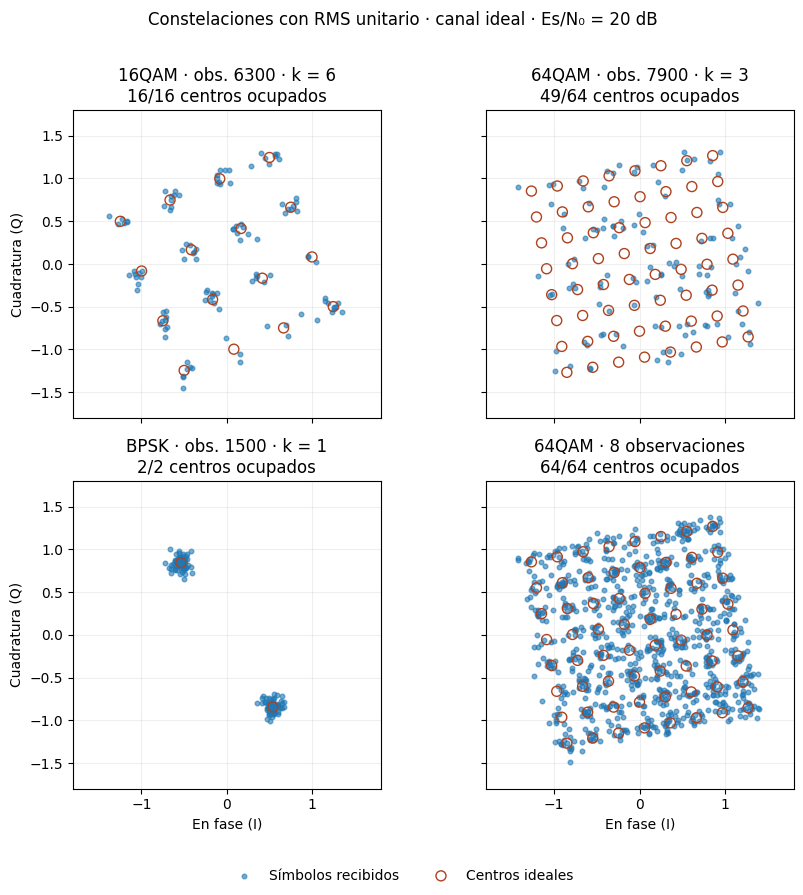

In [16]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

from src.constelacion import (
    a_complejo,
    filtro_adaptado,
    temporizacion,
    normalizar_rms,
)
from src.generator import constellation

carpeta = raiz / "data" / "ideal"
X = np.load(carpeta / "X.npy", mmap_mode="r")
meta = pd.read_csv(carpeta / "meta.csv")
ideal_20 = meta[(meta["channel"] == "ideal") & (meta["snr_db"] == 20)]

paneles = [("16QAM", 1), ("64QAM", 1), ("BPSK", 1), ("64QAM", 8)]
fig, ejes = plt.subplots(2, 2, figsize=(9, 9), sharex=True, sharey=True)

for ax, (mod, cantidad) in zip(ejes.flat, paneles):
    filas = ideal_20[ideal_20["mod"] == mod].head(cantidad)
    fase_ref = filas.iloc[0]["phase"]
    centros = constellation(mod) * np.exp(1j * fase_ref)

    bloques = []
    for i, fila in filas.iterrows():
        y = a_complejo(X[i])
        z = filtro_adaptado(y)
        s, k = temporizacion(z)
        s = normalizar_rms(s)

        # Con una observación, el ajuste vale 1 y se conserva el giro original.
        # Con varias, se llevan todas a la orientación de la primera.
        ajuste = np.exp(1j * (fase_ref - fila["phase"]))
        bloques.append(s * ajuste)

    puntos = np.concatenate(bloques)

    # Un centro cuenta como ocupado si es el más cercano a algún punto.
    distancias = np.abs(puntos[:, None] - centros)
    centro_mas_cercano = np.argmin(distancias, axis=1)
    ocupados = np.unique(centro_mas_cercano).size

    ax.scatter(
        puntos.real, puntos.imag,
        s=11, alpha=0.6, label="Símbolos recibidos",
    )
    ax.scatter(
        centros.real, centros.imag,
        s=52, facecolors="none", edgecolors="#af411d",
        linewidths=1, label="Centros ideales",
    )

    if cantidad == 1:
        detalle = f"obs. {filas.index[0]} · k = {k}"
    else:
        detalle = f"{len(filas)} observaciones"

    ax.set_title(f"{mod} · {detalle}\n{ocupados}/{len(centros)} centros ocupados")
    ax.set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect="equal")
    ax.grid(alpha=0.2)

for ax in ejes[:, 0]:
    ax.set_ylabel("Cuadratura (Q)")
for ax in ejes[-1, :]:
    ax.set_xlabel("En fase (I)")

fig.suptitle("Constelaciones con RMS unitario · canal ideal · Es/N₀ = 20 dB")
fig.legend(
    *ejes[0, 0].get_legend_handles_labels(),
    loc="lower center", ncol=2, frameon=False,
)
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
plt.show()

In [17]:
from importlib import reload
import src.constelacion as constelacion
reload(constelacion)

# Importar TODO después del reload: los nombres importados en la celda 11
# siguen apuntando a la versión vieja del módulo.
from src.constelacion import (
    a_complejo, filtro_adaptado, temporizacion, normalizar_rms,
    elegir_m, simbolos_corregidos,
)
from src.dataset import SPS, MODS

def cargar_split(nombre):
    carpeta = raiz / "data" / nombre
    X = np.load(carpeta / "X.npy", mmap_mode="r")
    meta = pd.read_csv(carpeta / "meta.csv")
    return X, meta

def medir(X, filas):
    resultados = []
    for i in filas.index:
        z = filtro_adaptado(a_complejo(X[i]))
        s, _ = temporizacion(z)
        resultados.append(elegir_m(normalizar_rms(s)))
    medidas = pd.DataFrame(resultados, index=filas.index,
                           columns=["M", "cfo_estimado", "fuerza"])
    tabla = filas[["mod", "snr_db", "cfo"]].join(medidas)
    tabla["cfo_real"] = tabla["cfo"] * SPS
    tabla["error"] = (tabla["cfo_estimado"] - tabla["cfo_real"]).abs()
    return tabla

X_ideal, meta_ideal = cargar_split("ideal")
filas_ideal = meta_ideal[meta_ideal["mod"].isin(MODS) & meta_ideal["snr_db"].eq(20)]
ideal = medir(X_ideal, filas_ideal)
# Un bin de la FFT dividido por el orden seleccionado, en ciclos/símbolo.
# M = 0 (sin línea) devuelve cfo = 0: cuenta como "a un bin de cero".
bin_m = 1 / (8192 * ideal["M"].where(ideal["M"] > 0, 4))
ideal["a_un_bin_de_cero"] = ideal["cfo_estimado"].abs() <= bin_m
print(ideal.groupby("mod").agg(n=("error", "size"), mediana_abs_cfo=("error", "median"),
                              fraccion_a_un_bin=("a_un_bin_de_cero", "mean")).to_string())


          n  mediana_abs_cfo  fraccion_a_un_bin
mod                                            
16APSK  100         0.000000               0.96
16QAM   100         0.000061               0.29
64QAM   100         0.000122               0.16
8PSK    100         0.000015               0.57
BPSK    100         0.000031               0.83
QPSK    100         0.000031               0.91


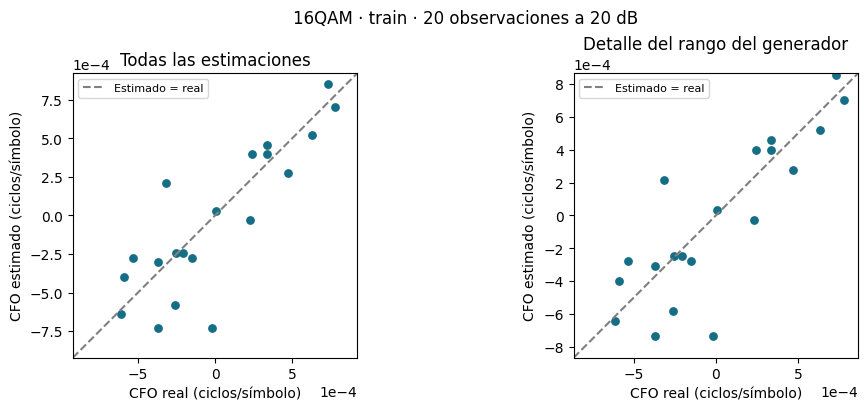

Fuera del rango físico de train: 1/20
Mediana del error absoluto: 0.000124 ciclos/símbolo


In [18]:
X_train, meta_train = cargar_split("train")
train = medir(X_train, meta_train[meta_train["mod"].isin(MODS)])
alta = train[train["snr_db"].eq(20)]
ejemplo = alta[alta["mod"].eq("16QAM")].sample(n=20, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
rango = 8e-4  # ±1e-4 ciclos/muestra × 8 muestras/símbolo
total = max(rango, ejemplo["cfo_estimado"].abs().max())
for ax, limite, titulo in zip(axes, [1.08 * total, 1.08 * rango],
                             ["Todas las estimaciones", "Detalle del rango del generador"]):
    ax.plot([-limite, limite], [-limite, limite], "--", color="gray", label="Estimado = real")
    ax.scatter(ejemplo["cfo_real"], ejemplo["cfo_estimado"], s=28, color="#166d86")
    ax.set(xlim=(-limite, limite), ylim=(-limite, limite), aspect="equal", title=titulo,
           xlabel="CFO real (ciclos/símbolo)", ylabel="CFO estimado (ciclos/símbolo)")
    ax.ticklabel_format(style="sci", axis="both", scilimits=(0, 0))
    ax.legend(fontsize=8)
fig.suptitle("16QAM · train · 20 observaciones a 20 dB")
plt.show()
print(f"Fuera del rango físico de train: {(ejemplo['cfo_estimado'].abs() > rango).sum()}/20")
print(f"Mediana del error absoluto: {ejemplo['error'].median():.3g} ciclos/símbolo")


In [19]:
conteo = pd.crosstab(alta["mod"], alta["M"]).reindex(index=MODS, columns=[0, 4, 8], fill_value=0)
print(conteo.to_string())


M         0    4    8
mod                  
BPSK     16  484    0
QPSK     14  486    0
8PSK     66    6  428
16QAM    49  451    0
64QAM    82  416    2
16APSK  470   10   20


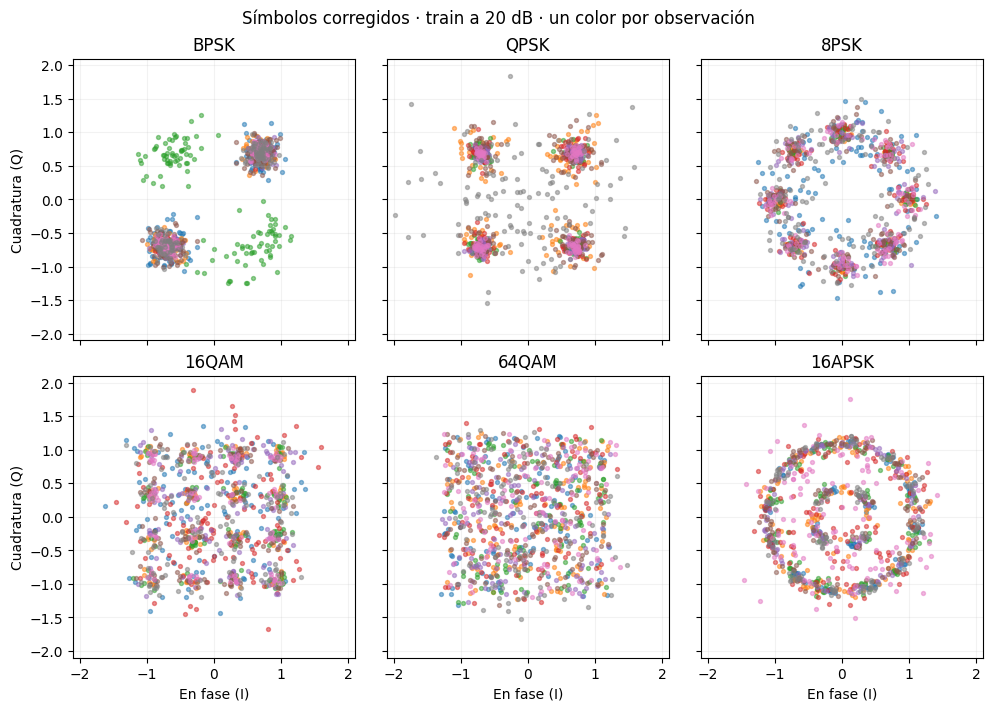

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, mod in zip(axes.flat, MODS):
    indices = alta[alta["mod"].eq(mod)].index[:8]
    for i in indices:
        s = simbolos_corregidos(X_train[i])
        ax.scatter(s.real, s.imag, s=8, alpha=0.50)
    ax.set(title=mod, aspect="equal", xlim=(-2.1, 2.1), ylim=(-2.1, 2.1))
    ax.grid(alpha=0.16)
for ax in axes[-1]:
    ax.set_xlabel("En fase (I)")
for ax in axes[:, 0]:
    ax.set_ylabel("Cuadratura (Q)")
fig.suptitle("Símbolos corregidos · train a 20 dB · un color por observación")
plt.show()


        mediana  referencia_cero
snr_db                          
-10.0  0.000391         0.000388
-8.0   0.000396         0.000394
-6.0   0.000397         0.000394
-4.0   0.000402         0.000399
-2.0   0.000396         0.000393
 0.0   0.000391         0.000394
 2.0   0.000385         0.000407
 4.0   0.000336         0.000376
 6.0    0.00033         0.000409
 8.0   0.000276         0.000398
 10.0  0.000229         0.000398
 12.0  0.000171         0.000401
 14.0  0.000139           0.0004
 16.0  0.000103         0.000387
 18.0  9.37e-05         0.000397
 20.0   7.3e-05         0.000407


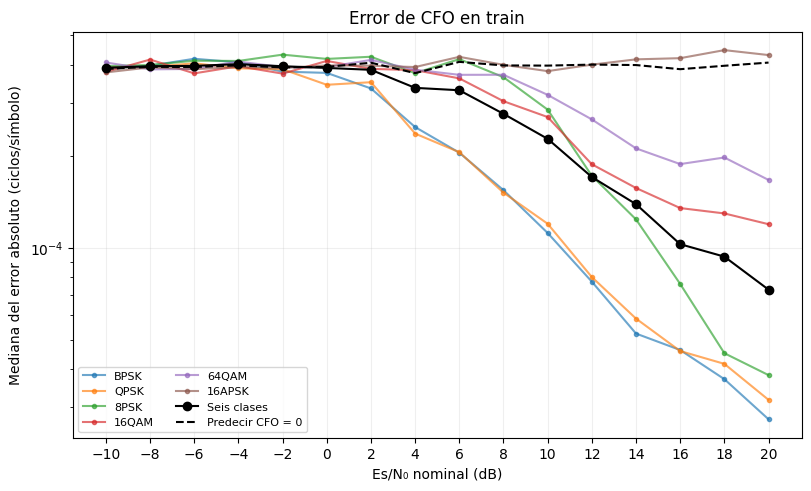

Primer SNR al descender donde la mediana alcanza o supera la referencia: -2 dB.


In [21]:
# Referencia: error que se obtiene al devolver CFO=0 para cada observación.
def resumir_error(tabla):
    return tabla.assign(error_cero=tabla["cfo_real"].abs()).groupby("snr_db").agg(
        mediana=("error", "median"), referencia_cero=("error_cero", "median")
    )

global_snr = resumir_error(train)
por_mod = train.pivot_table(index="snr_db", columns="mod", values="error", aggfunc="median")
print(global_snr.to_string(float_format=lambda x: f"{x:.3g}"))

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
for mod in MODS:
    ax.semilogy(por_mod.index, por_mod[mod], marker=".", alpha=0.65, label=mod)
ax.semilogy(global_snr.index, global_snr.mediana, "ko-", label="Seis clases")
ax.semilogy(global_snr.index, global_snr.referencia_cero, "k--", label="Predecir CFO = 0")
ax.set(xlabel="Es/N₀ nominal (dB)", ylabel="Mediana del error absoluto (ciclos/símbolo)",
       title="Error de CFO en train", xticks=global_snr.index)
ax.grid(alpha=0.2)
ax.legend(ncol=2, fontsize=8)
plt.show()

# Recorremos el SNR desde +20 dB hacia abajo hasta perder la ventaja sobre cero.
pierde = global_snr[global_snr.mediana >= global_snr.referencia_cero]
if pierde.empty:
    print("La mediana mejora la referencia en todo el barrido.")
else:
    print(f"Primer SNR al descender donde la mediana alcanza o supera la referencia: {pierde.index.max():g} dB.")


### Resultados de la comprobación

Versión corregida el 2026-11-25. Cambios en `estimar_cfo` y `elegir_m`:
- el pico se busca solo en |f| ≤ M · 3e-3 ciclos/símbolo;
- la fuerza se normaliza con la norma 2: un tono puro da 1 y el ruido da ≈ 1/√118 ≈ 0,09;
- el umbral es 0,22, calibrado con el piso de ruido de train;
- se prefiere M = 4, y M = 0 significa "sin línea, sin corrección".

**ideal a 20 dB.** La mediana de |CFO estimado| queda en 1,2e-4 ciclos/símbolo o menos en las seis clases. En 16APSK es 0: no aparece línea en 96 de 100 observaciones y no se corrige nada.

**train, 16QAM a 20 dB (20 observaciones).** Una de 20 queda fuera de ±8e-4 (antes eran 4). La mediana del error es 1,24e-4 ciclos/símbolo. Incluye las observaciones sin línea, donde el error es igual a |CFO real|.

**Elección de M en train a 20 dB (500 por clase).**
- BPSK, QPSK, 16QAM y 64QAM eligen M = 4 (484, 486, 451 y 416).
- 8PSK elige M = 8 (428).
- 16APSK queda sin línea en 470.
- M = 8 en QAM no da un CFO equivocado, porque 8 es múltiplo de 4. El problema es que deja la fase conocida solo módulo 45°, y la rejilla salía en rombo en la mitad de las observaciones. Por eso se prefiere M = 4.

**Por qué 16APSK no tiene línea.** El anillo externo tiene 12 puntos en π/12 + 2πm/12. En s⁴ y en s⁸ caen en 3 direcciones separadas 120°, que suman cero. Solo aporta el anillo interno, con r ≈ 0,44. Sin línea no se corrige nada, y los anillos quedan con un giro al azar.

**Figura de símbolos corregidos.**
- 16QAM queda cuadrada en las 8 observaciones.
- BPSK queda en dos diagonales por la ambigüedad de 90° de M = 4.
- La dispersión de la QPSK gris y de la BPSK verde viene del fading: desvanecimiento profundo y algo de ISI, que esta cadena no corrige. Es el riesgo anotado en la tarea.

**Para el informe.** El error de CFO baja de forma monótona con el SNR: 7,3e-5 a 20 dB y 1,39e-4 a 14 dB (antes del arreglo era 3,65e-3). De −2 dB hacia abajo, la mediana empata con "predecir CFO = 0" (diferencia < 1 %), porque casi todas las observaciones caen en M = 0. El umbral evita meter un CFO falso.


(32, 32) float32 | suma = 0.992


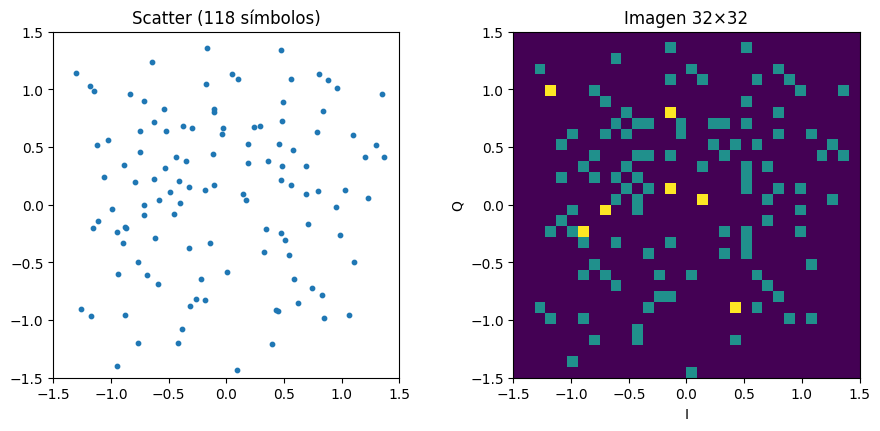

In [ ]:
reload(constelacion)
from src.constelacion import imagen_constelacion, simbolos_corregidos

# Misma 16QAM que el primer color del panel 16QAM de la celda 15.
i = alta[alta["mod"].eq("16QAM")].index[0]
img = imagen_constelacion(X_train[i])
print(img.shape, img.dtype, "| suma =", round(float(img.sum()), 3))

s = simbolos_corregidos(X_train[i])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2), constrained_layout=True)
ax1.scatter(s.real, s.imag, s=10)
ax1.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal", title="Scatter (118 símbolos)")

# origin="lower": la fila 0 va abajo, como el eje Q.
# extent: los ejes muestran valores de I y Q en vez de índices de píxel 0..31.
ax2.imshow(img, origin="lower", extent=(-1.5, 1.5, -1.5, 1.5))
ax2.set(title="Imagen 32×32", xlabel="I", ylabel="Q")
plt.show()

#Qué comprobar: la forma es (32, 32), el tipo es float32 y la suma da ≤ 1. Cada mancha de la imagen debe coincidir con una nube del scatter.


In [25]:
# groupby(...).head(50): las primeras 50 filas de cada combinación (SNR, clase).
# 16 SNR x 6 clases x 50 = 4800 observaciones, unos 2 s.
muestra = (meta_train[meta_train["mod"].isin(MODS)]
           .groupby(["snr_db", "mod"]).head(50))

# 1 - suma = fracción de símbolos que cayó fuera de [-1.5, 1.5]².
fuera = [1 - imagen_constelacion(X_train[i]).sum() for i in muestra.index]
muestra = muestra.assign(fuera=fuera)

print(muestra.pivot_table(index="snr_db", columns="mod", values="fuera",
                          aggfunc="mean").round(3).to_string())

#Qué comprobar: a 20 dB debe dar casi 0. Anota cuánto da a −10 dB.

mod     16APSK  16QAM  64QAM   8PSK   BPSK   QPSK
snr_db                                           
-10.0    0.061  0.071  0.066  0.067  0.063  0.068
-8.0     0.058  0.063  0.067  0.066  0.062  0.067
-6.0     0.065  0.065  0.065  0.067  0.066  0.063
-4.0     0.061  0.062  0.063  0.063  0.060  0.063
-2.0     0.064  0.058  0.063  0.054  0.059  0.052
 0.0     0.058  0.057  0.058  0.053  0.051  0.048
 2.0     0.054  0.048  0.057  0.043  0.046  0.039
 4.0     0.044  0.048  0.048  0.039  0.034  0.032
 6.0     0.041  0.041  0.042  0.033  0.029  0.024
 8.0     0.025  0.026  0.035  0.021  0.018  0.021
 10.0    0.026  0.023  0.018  0.016  0.015  0.013
 12.0    0.015  0.012  0.020  0.009  0.010  0.010
 14.0    0.010  0.007  0.013  0.008  0.006  0.008
 16.0    0.011  0.005  0.011  0.004  0.003  0.005
 18.0    0.003  0.004  0.008  0.006  0.002  0.002
 20.0    0.005  0.004  0.005  0.002  0.001  0.004


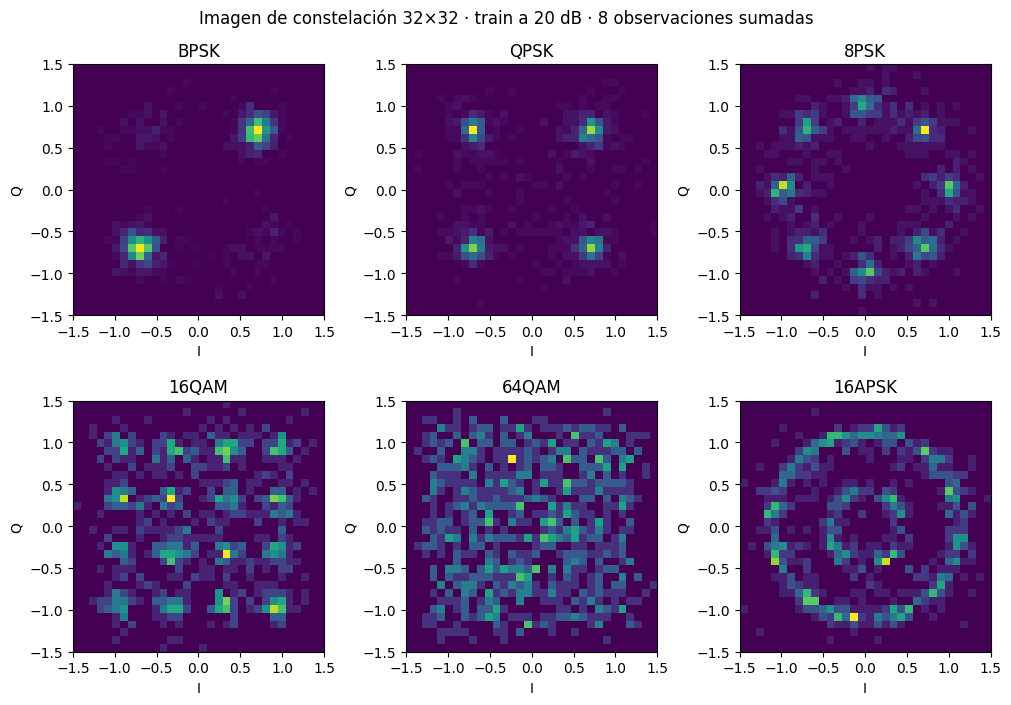

In [26]:
carpeta_figs = raiz / "figs" / "cnn2d"
# parents=True crea también las carpetas intermedias; exist_ok=True no falla si ya existe.
carpeta_figs.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(10, 7), constrained_layout=True)
for ax, mod in zip(axes.flat, MODS):
    indices = alta[alta["mod"].eq(mod)].index[:8]
    # sum() de arreglos (32, 32) los suma píxel a píxel: 8 observaciones en una imagen.
    suma = sum(imagen_constelacion(X_train[i]) for i in indices)
    ax.imshow(suma, origin="lower", extent=(-1.5, 1.5, -1.5, 1.5))
    ax.set(title=mod, xlabel="I", ylabel="Q")

fig.suptitle("Imagen de constelación 32×32 · train a 20 dB · 8 observaciones sumadas")
fig.savefig(carpeta_figs / "01_imagenes_por_clase.png", dpi=120)
plt.show()

In [27]:
import json
import time

from src.constelacion import (
    imagen_constelacion, N_BINS, RANGO_IMAGEN, UMBRAL_LINEA, CFO_MAX_SIMBOLO,
)

# ideal y exp6 también: sirven para meter la CNN 2D en la tabla del Exp. 6.
SPLITS = ("train", "val", "test", "ideal", "exp6")

for nombre in SPLITS:
    carpeta = raiz / "data" / nombre
    # X_split y no X: X ya es el set ideal en las celdas de arriba.
    X_split = np.load(carpeta / "X.npy", mmap_mode="r")
    n = X_split.shape[0]

    # np.empty reserva memoria sin llenarla (más rápido que np.zeros).
    # Todas las posiciones se sobrescriben en el bucle, así que no queda basura.
    imgs = np.empty((n, N_BINS, N_BINS), dtype=np.float32)

    # perf_counter: reloj de alta resolución para medir duraciones.
    t0 = time.perf_counter()
    for i in range(n):
        imgs[i] = imagen_constelacion(X_split[i])
    dt = time.perf_counter() - t0

    # np.save escribe el arreglo en formato .npy (forma + dtype + datos crudos).
    np.save(carpeta / "img32.npy", imgs)

    info = {
        "shape": list(imgs.shape),
        "dtype": "float32",
        "source": "X.npy",
        "metadata": "meta.csv",
        "row_order": "Idéntico a X.npy y meta.csv",
        "funcion": "src.constelacion.imagen_constelacion",
        "cadena": "filtro adaptado RRC -> temporización (máx. energía) -> RMS = 1 "
                  "-> CFO y fase por potencia M-ésima (M = 4, 8 o 0 sin línea) -> histogram2d",
        "bins": N_BINS,
        "rango": [-RANGO_IMAGEN, RANGO_IMAGEN],
        "valor_pixel": "fracción de los 118 símbolos que cae en el píxel",
        "filas_columnas": "fila = bin de Q (origin='lower'), columna = bin de I",
        "umbral_linea": UMBRAL_LINEA,
        "cfo_max_ciclos_por_simbolo": CFO_MAX_SIMBOLO,
        "creado": time.strftime("%Y-%m-%d"),
    }
    # ensure_ascii=False deja las tildes legibles en el archivo.
    with open(carpeta / "img32_info.json", "w", encoding="utf-8") as f:
        json.dump(info, f, indent=2, ensure_ascii=False)

    print(f"{nombre}: {imgs.shape} en {dt:.1f} s ({dt / n * 1e3:.2f} ms/obs)")

    # del borra el nombre; Python libera los ~230 MB de train antes del siguiente split.
    del imgs

train: (56000, 32, 32) en 25.8 s (0.46 ms/obs)
val: (11200, 32, 32) en 5.8 s (0.51 ms/obs)
test: (11200, 32, 32) en 5.6 s (0.50 ms/obs)
ideal: (11200, 32, 32) en 5.9 s (0.53 ms/obs)
exp6: (11200, 32, 32) en 6.1 s (0.54 ms/obs)


In [28]:
rng = np.random.default_rng(0)

for nombre in SPLITS:
    carpeta = raiz / "data" / nombre
    # Se relee del disco: si algo se guardó mal, aparece aquí y no en memoria.
    imgs = np.load(carpeta / "img32.npy", mmap_mode="r")
    X_split = np.load(carpeta / "X.npy", mmap_mode="r")
    filas_meta = len(pd.read_csv(carpeta / "meta.csv"))

    # sum(axis=(1, 2)) suma filas y columnas de cada imagen: un número por observación.
    # Entrada: (N, 32, 32) -> Salida: (N,)
    sumas = imgs.sum(axis=(1, 2))

    # 5 índices distintos al azar (replace=False: sin repetir).
    muestra = rng.choice(len(imgs), size=5, replace=False)
    # array_equal: True solo si forma y todos los valores coinciden exactamente.
    iguales = all(np.array_equal(imgs[i], imagen_constelacion(X_split[i])) for i in muestra)

    print(f"{nombre:6s} {imgs.shape} | meta: {filas_meta} filas | "
          f"NaN: {bool(np.isnan(imgs).any())} | "
          f"suma en [{sumas.min():.3f}, {sumas.max():.3f}] | "
          f"5 al azar iguales: {iguales}")

train  (56000, 32, 32) | meta: 56000 filas | NaN: False | suma en [0.856, 1.000] | 5 al azar iguales: True
val    (11200, 32, 32) | meta: 11200 filas | NaN: False | suma en [0.873, 1.000] | 5 al azar iguales: True
test   (11200, 32, 32) | meta: 11200 filas | NaN: False | suma en [0.873, 1.000] | 5 al azar iguales: True
ideal  (11200, 32, 32) | meta: 11200 filas | NaN: False | suma en [0.873, 1.000] | 5 al azar iguales: True
exp6   (11200, 32, 32) | meta: 11200 filas | NaN: False | suma en [0.873, 1.000] | 5 al azar iguales: True
